# Khử nhiễu, phát hiện bất thường và lịch dự đoán bảo trì trên FD001

**Học viên:** Phan Nguyễn Mai Phương  
**MSHV:** 25002711

Notebook này rà soát ba bước cuối của pipeline Đề tài 8, theo đúng thứ tự chạy:

1. Khử nhiễu từng sensor bằng EWMA (`outputs/degradation/`).
2. Tạo Health Index từ tín hiệu đã khử nhiễu và phát hiện dấu hiệu bất thường.
3. Ghép dự đoán RUL với tín hiệu bất thường thành lịch bảo trì cho 100 động cơ test
   (`outputs/maintenance/`), rồi mới dùng nhãn test để kiểm tra.

Mỗi kết quả được tính lại bằng chính các hàm của `cmapss.degradation` và
`cmapss.maintenance`, sau đó so với artifact đã lưu bằng `assert`. Notebook không
fit mô hình RUL và không ghi file.

```text
train_FD001.txt ─> EWMA span 10 ─> Health Index (StandardScaler + PCA fit trên train)
                                          └─> z ≤ −3 trong 5 cycle liên tiếp: cảnh báo mức 1
test_FD001.txt ──> EWMA ─> Health Index (chỉ transform) ─> trạng thái bất thường ─┐
final_predictions.parquet (RUL dự đoán) ──────────────────────────────────────────┴─> lịch bảo trì
                                                                                        └─> RUL_FD001.txt (đọc sau cùng)
```

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "outputs").is_dir():
    ROOT = ROOT.parent  # notebook được mở từ thư mục notebooks/
assert (ROOT / "outputs").is_dir(), "Chạy notebook từ thư mục gốc repository"

pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})


def read_json(relative: str) -> dict:
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))

from cmapss.data.readers import read_observations, read_test_labels
from cmapss.degradation import (
    INFORMATIVE_SENSORS, AnomalyConfig, detect_anomalies, ewma_smooth, noise_summary, sensitivity_grid,
)
from cmapss.degradation.cli import EWMA_SPAN
from cmapss.maintenance import (
    STATUS_ORDER,
    MaintenanceConfig,
    anomaly_status,
    build_schedule,
    evaluate_schedule,
    transform_health_index,
)
from cmapss.timeseries.health_index import fit_health_index

degradation_summary = read_json("outputs/degradation/summary.json")
maintenance_summary = read_json("outputs/maintenance/summary.json")
train = read_observations(ROOT / "data/raw/train_FD001.txt", split="train")
test = read_observations(ROOT / "data/raw/test_FD001.txt", split="test")
print(f"train: {len(train):,} dòng, {train['engine_id'].nunique()} động cơ")
print(f"test:  {len(test):,} dòng, {test['engine_id'].nunique()} động cơ")

%matplotlib inline

train: 20,631 dòng, 100 động cơ
test:  13,096 dòng, 100 động cơ


## 1. Khử nhiễu bằng EWMA

EWMA (exponentially weighted moving average, trung bình trượt có trọng số mũ) làm
mượt từng sensor trong từng động cơ:

$$s_t = \alpha\,x_t + (1-\alpha)\,s_{t-1},\qquad s_1 = x_1,\qquad \alpha = \frac{2}{\text{span}+1}.$$

Với span 10 thì $\alpha \approx 0{,}18$: giá trị mới chiếm 18%, phần còn lại là
lịch sử đã làm mượt. Ô dưới đây kiểm tra công thức trên một ví dụ tính tay
(span 3, $\alpha = 0{,}5$) và kiểm tra tính nhân quả: đổi giá trị ở cycle cuối
không được làm đổi các cycle trước đó.

In [2]:
toy = pd.DataFrame({"engine_id": 1, "cycle": [1, 2, 3], "x": [0.0, 4.0, 8.0]})
smoothed_toy = ewma_smooth(toy, ["x"], span=3)
print(smoothed_toy["x"].tolist())  # 0; 0,5·4 + 0,5·0 = 2; 0,5·8 + 0,5·2 = 5
assert smoothed_toy["x"].tolist() == [0.0, 2.0, 5.0]

changed = toy.copy()
changed.loc[2, "x"] = 999.0
assert ewma_smooth(changed, ["x"], span=3)["x"].iloc[:2].tolist() == smoothed_toy["x"].iloc[:2].tolist()
print("EWMA chỉ dùng cycle hiện tại và quá khứ.")

[0.0, 2.0, 5.0]
EWMA chỉ dùng cycle hiện tại và quá khứ.


Áp dụng cho 14 sensor có xu hướng (bảy sensor còn lại hằng hoặc gần hằng). Mức khử
nhiễu được đo bằng độ lệch chuẩn của sai phân $x_t - x_{t-1}$ trong từng động cơ:
xu hướng suy giảm thay đổi chậm nên đóng góp ít vào sai phân, còn dao động giữa hai
cycle liền kề đóng góp phần lớn.

In [3]:
assert degradation_summary["ewma_span"] == EWMA_SPAN == 10
smoothed = ewma_smooth(train, INFORMATIVE_SENSORS, span=EWMA_SPAN)
noise = noise_summary(train, smoothed, INFORMATIVE_SENSORS)

stored_noise = pd.read_csv(ROOT / "outputs/degradation/tables/noise_summary.csv")
assert np.allclose(noise[["diff_std_raw", "diff_std_smoothed", "reduction_pct"]],
                   stored_noise[["diff_std_raw", "diff_std_smoothed", "reduction_pct"]], rtol=1e-9)
assert np.isclose(noise["reduction_pct"].median(), degradation_summary["noise_reduction_pct_median"])
print(f"Mức giảm dao động: trung vị {noise['reduction_pct'].median():.1f}%, "
      f"từ {noise['reduction_pct'].min():.1f}% đến {noise['reduction_pct'].max():.1f}%")
noise.round(4)

Mức giảm dao động: trung vị 86.3%, từ 83.6% đến 86.4%


,sensor,diff_std_raw,diff_std_smoothed,reduction_pct
0,sensor_2,0.4270,0.0583,86.3422
1,sensor_3,5.6575,0.7715,86.3635
2,sensor_4,5.6994,0.7829,86.2626
3,sensor_7,0.5773,0.0789,86.3367
4,sensor_8,0.0428,0.0060,86.0672
5,sensor_9,5.9037,0.9241,84.3473
6,sensor_11,0.1436,0.0198,86.1785
7,sensor_12,0.4245,0.0588,86.1550
8,sensor_13,0.0430,0.0060,86.0069
9,sensor_14,4.4532,0.7285,83.6408


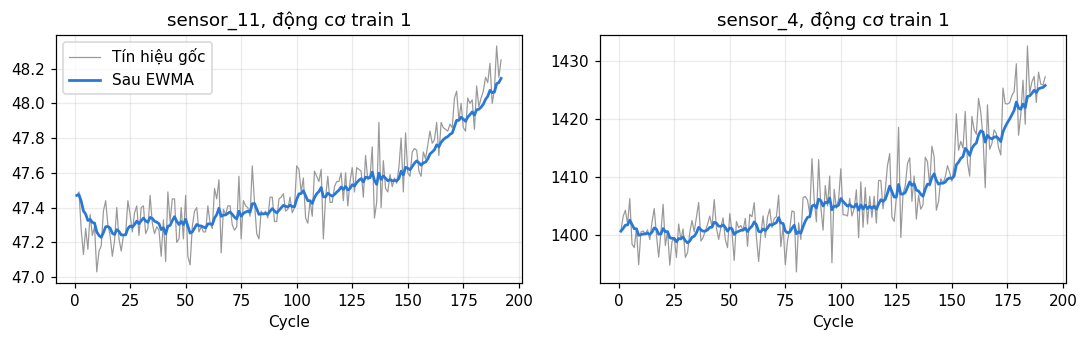

In [4]:
engine = 1
raw_engine = train[train["engine_id"] == engine]
smooth_engine = smoothed[smoothed["engine_id"] == engine]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, sensor in zip(axes, ["sensor_11", "sensor_4"]):
    ax.plot(raw_engine["cycle"], raw_engine[sensor], color="0.6", linewidth=0.8, label="Tín hiệu gốc")
    ax.plot(smooth_engine["cycle"], smooth_engine[sensor], color="#2a78d6", linewidth=1.8, label="Sau EWMA")
    ax.set(title=f"{sensor}, động cơ train {engine}", xlabel="Cycle")
axes[0].legend()
plt.tight_layout()
plt.show()

Đường xanh vẫn giữ hướng tăng của `sensor_11` và `sensor_4`, đặc biệt đoạn tăng
nhanh sau cycle 150, nhưng bỏ phần lớn các gai ngắn hạn. Mức giảm gần như bằng nhau
ở mọi sensor (khoảng 84–86%), phù hợp với giả định dao động ngắn hạn gần độc lập
giữa các cycle. Đây là mức giảm dao động, chưa chứng minh đã loại đúng nhiễu đo, vì
dữ liệu không có tín hiệu sạch để đối chiếu.

## 2. Health Index và phát hiện dấu hiệu bất thường

Health Index gộp 21 sensor đã khử nhiễu thành một chuỗi: StandardScaler, chiếu lên
thành phần chính thứ nhất của PCA, đổi dấu để chỉ số giảm theo cycle, rồi chuẩn hóa
về trung bình 0 và độ lệch chuẩn 1. Bước này không dùng nhãn RUL.

Mỗi động cơ được so sánh với chính nó ở giai đoạn vận hành ổn định đầu vòng đời.
Gọi $\mu_i, \sigma_i$ là trung bình và
độ lệch chuẩn Health Index trong 30 cycle đầu; $z_{i,t} = (h_{i,t} - \mu_i)/\sigma_i$.
Động cơ được báo bất thường tại cycle đầu tiên mà $z \le -3$ đã giữ 5 cycle liên tiếp.

In [5]:
config = AnomalyConfig()
stored_config = degradation_summary["anomaly_config"]
assert (config.baseline_cycles, config.z_threshold, config.persistence) == (
    stored_config["baseline_cycles"], stored_config["z_threshold"], stored_config["persistence"])

fitted_train = fit_health_index(smoothed)
health_index = fitted_train.health_index
signals = pd.read_parquet(ROOT / "outputs/degradation/tables/signals.parquet")
merged = health_index.merge(signals[["engine_id", "cycle", "health_index_ewma"]], on=["engine_id", "cycle"])
assert len(merged) == len(train) and np.allclose(merged["health_index"], merged["health_index_ewma"], rtol=1e-9)

events = detect_anomalies(health_index, config, column="health_index")
stored_events = pd.read_csv(ROOT / "outputs/degradation/tables/anomaly_events.csv")
assert events["detection_cycle"].astype(float).tolist() == stored_events["detection_cycle"].astype(float).tolist()
leads = events["lead_cycles"].astype(float)
print(f"Phát hiện {int(events['detected'].sum())}/{len(events)} động cơ trước khi hỏng")
print(f"Số cycle từ lúc phát hiện đến khi hỏng: trung vị {leads.median():.0f}, "
      f"tứ phân vị {leads.quantile(0.25):.0f}–{leads.quantile(0.75):.0f}, nhỏ nhất {leads.min():.0f}")
events.head()

Phát hiện 100/100 động cơ trước khi hỏng
Số cycle từ lúc phát hiện đến khi hỏng: trung vị 121, tứ phân vị 101–149, nhỏ nhất 67


,engine_id,failure_cycle,baseline_mean,baseline_std,detection_cycle,lead_cycles,detected
0,1,192,0.9368,0.0688,84,108,True
1,2,287,1.6531,0.0771,72,215,True
2,3,179,1.1586,0.0506,64,115,True
3,4,189,0.6622,0.0625,77,112,True
4,5,269,1.5350,0.0753,86,183,True


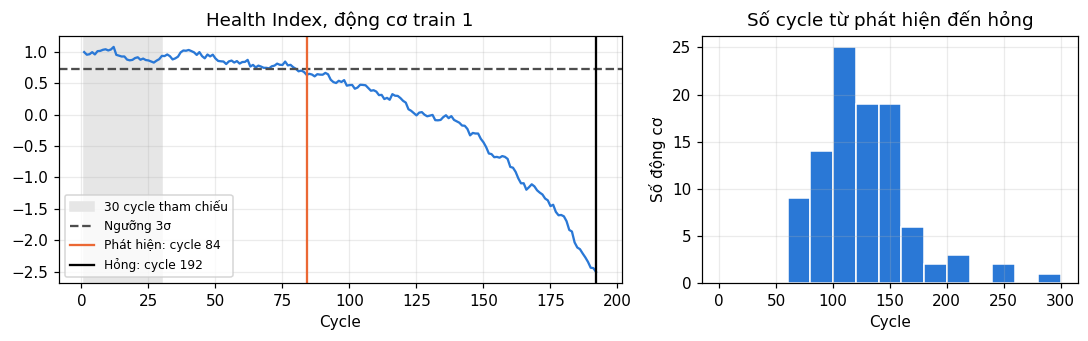

In [6]:
event = events.set_index("engine_id").loc[engine]
curve = health_index[health_index["engine_id"] == engine]
threshold = event["baseline_mean"] - config.z_threshold * event["baseline_std"]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"width_ratios": [1.5, 1]})
left.plot(curve["cycle"], curve["health_index"], color="#2a78d6")
left.axvspan(1, config.baseline_cycles, color="0.9", label="30 cycle tham chiếu")
left.axhline(threshold, color="0.3", linestyle="--", label="Ngưỡng 3σ")
left.axvline(event["detection_cycle"], color="#eb6834", label=f"Phát hiện: cycle {int(event['detection_cycle'])}")
left.axvline(event["failure_cycle"], color="black", label=f"Hỏng: cycle {int(event['failure_cycle'])}")
left.set(title=f"Health Index, động cơ train {engine}", xlabel="Cycle")
left.legend(fontsize=8)
right.hist(leads, bins=range(0, int(leads.max()) + 20, 20), color="#2a78d6", edgecolor="white")
right.set(title="Số cycle từ phát hiện đến hỏng", xlabel="Cycle", ylabel="Số động cơ")
plt.tight_layout()
plt.show()

Khử nhiễu ảnh hưởng trực tiếp đến kết quả. Ô dưới đây chạy cùng quy tắc trên
Health Index từ tín hiệu gốc: độ lệch chuẩn tham chiếu lớn hơn nên ngưỡng $3\sigma$
nằm xa hơn và dấu hiệu bất thường xuất hiện muộn hơn.

In [7]:
events_raw = detect_anomalies(fit_health_index(train).health_index, config, column="health_index")
comparison = pd.DataFrame({
    "Trung vị số cycle báo trước": [leads.median(), events_raw["lead_cycles"].astype(float).median()],
    "Trung vị % vòng đời lúc phát hiện": [
        (events["detection_cycle"] / events["failure_cycle"]).median() * 100,
        (events_raw["detection_cycle"] / events_raw["failure_cycle"]).median() * 100,
    ],
}, index=["Sau khử nhiễu", "Tín hiệu gốc"])
assert np.isclose(comparison.iloc[1, 0], degradation_summary["anomaly_raw_for_comparison"]["lead_median"])
comparison.round(1)

,Trung vị số cycle báo trước,Trung vị % vòng đời lúc phát hiện
Sau khử nhiễu,121.0,39.1
Tín hiệu gốc,72.5,61.7


Báo sớm hơn không tự động là tốt hơn. Mọi động cơ train đều đi đến hỏng và dữ liệu
không ghi lúc bắt đầu suy giảm, nên chưa đo được tỷ lệ dương tính giả. Vì vậy đây là
cảnh báo mức 1: động cơ đã lệch khỏi trạng thái vận hành ổn định, chưa ước lượng
thời gian còn lại.

### Phân tích độ nhạy của quy tắc

Ngưỡng $3\sigma$ và 5 cycle liên tiếp là lựa chọn cố định trước. Ô dưới đây chạy lại
quy tắc trên lưới $z \in \{2, 3, 4\}$ × số cycle liên tiếp $\in \{3, 5, 10\}$.
Cột `n_early` đếm động cơ bị báo trong 10 cycle ngay sau đoạn tham chiếu (cycle 31–40);
báo động sớm như vậy nhiều khả năng do dao động, nên được dùng làm chỉ báo gián tiếp
cho độ nhạy quá mức khi không có nhãn bất thường.

In [8]:
sensitivity = sensitivity_grid(health_index, column="health_index")
stored_sensitivity = pd.read_csv(ROOT / "outputs/degradation/tables/anomaly_sensitivity.csv")
stored_ewma = stored_sensitivity[stored_sensitivity["signal"] == "ewma"].drop(columns="signal").reset_index(drop=True)
pd.testing.assert_frame_equal(sensitivity, stored_ewma, check_dtype=False)
sensitivity.assign(life_fraction_median=lambda d: (d["life_fraction_median"] * 100).round(1))

,z_threshold,persistence,n_engines,n_detected,lead_min,lead_median,life_fraction_median,n_early
0,2.0,3,100,100,78.0,136.0,29.6,17
1,2.0,5,100,100,76.0,132.5,32.8,8
2,2.0,10,100,100,71.0,124.0,37.6,0
3,3.0,3,100,100,77.0,127.0,35.8,2
4,3.0,5,100,100,67.0,121.0,39.1,1
5,3.0,10,100,100,62.0,110.5,44.4,0
6,4.0,3,100,100,62.0,114.5,42.8,1
7,4.0,5,100,100,60.0,109.0,45.0,1
8,4.0,10,100,100,50.0,98.5,49.2,0


Cả 9 cấu hình đều phát hiện đủ 100 động cơ trước khi hỏng, nên lựa chọn tham số là
đánh đổi giữa thời gian báo trước và rủi ro báo quá sớm. Ngưỡng $2\sigma$ với 3 cycle
báo 17 động cơ ngay trong cycle 31–40; ngưỡng $4\sigma$ với 10 cycle không báo sớm
nhưng mất khoảng 22 cycle báo trước so với cấu hình đã chọn. Cấu hình $3\sigma$, 5 cycle
nằm giữa: một trường hợp báo sớm, trung vị 121 cycle báo trước, lead time nhỏ nhất
67 cycle, vẫn lớn hơn ngưỡng cảnh báo mức 2 (30 cycle).

## 3. Lịch dự đoán thời điểm cần bảo trì

Với mỗi động cơ test tại cycle cuối được quan sát $t_i$ và RUL dự đoán $\hat y_i$:

$$c_i = \max(\lfloor \hat y_i - 30 \rfloor, 0),\qquad m_i = t_i + c_i,$$

trong đó $c_i$ là số cycle còn lại đến lúc cần bảo trì và $m_i$ là cycle cần bảo trì.
Trạng thái theo thứ tự ưu tiên: **cần bảo trì** nếu $\hat y_i \le 30$; **theo dõi
tăng cường** nếu Health Index đã báo bất thường; còn lại **bình thường**.

Health Index của động cơ test dùng đúng scaler, PCA và hệ số chuẩn hóa đã fit trên
train, không fit lại. Động cơ dưới 35 cycle (30 tham chiếu + 5 liên tiếp) được ghi là
chưa đủ dữ liệu để đánh giá bất thường.

In [9]:
test_smoothed = ewma_smooth(test, INFORMATIVE_SENSORS, span=EWMA_SPAN)
test_health_index = transform_health_index(fitted_train, test_smoothed)
stored_test_hi = pd.read_parquet(ROOT / "outputs/maintenance/tables/test_health_index.parquet")
assert np.allclose(test_health_index["health_index"], stored_test_hi["health_index"], rtol=1e-9)

anomalies = anomaly_status(test_health_index, config)
predictions = pd.read_parquet(ROOT / "outputs/modeling/predictions/final_predictions.parquet")
schedule = build_schedule(predictions, anomalies, MaintenanceConfig())

stored_schedule = pd.read_csv(ROOT / "outputs/maintenance/tables/maintenance_schedule.csv")
assert schedule["engine_id"].tolist() == stored_schedule["engine_id"].tolist()
assert schedule["status"].tolist() == stored_schedule["status"].tolist()
assert schedule["maintenance_cycle"].tolist() == stored_schedule["maintenance_cycle"].tolist()
print(schedule["status"].value_counts().reindex(STATUS_ORDER).to_string())
print("Chưa đủ dữ liệu đánh giá bất thường:", anomalies.loc[~anomalies["anomaly_evaluable"], "engine_id"].tolist())
schedule.head(10)

status
Cần bảo trì            21
Theo dõi tăng cường    59
Bình thường            20
Chưa đủ dữ liệu đánh giá bất thường: [1, 85]


,priority,engine_id,current_cycle,rul_pred,cycles_to_maintenance,maintenance_cycle,predicted_failure_cycle,anomaly_evaluable,anomaly_detected,anomaly_cycle,status
0,1,34,203,6.1789,0,203,209,True,True,70,Cần bảo trì
1,2,81,213,6.6710,0,213,219,True,True,80,Cần bảo trì
2,3,76,205,6.8965,0,205,211,True,True,104,Cần bảo trì
3,4,31,196,8.1032,0,196,204,True,True,66,Cần bảo trì
4,5,68,187,8.7956,0,187,195,True,True,101,Cần bảo trì
5,6,49,303,9.0748,0,303,312,True,True,133,Cần bảo trì
6,7,20,184,9.8732,0,184,193,True,True,67,Cần bảo trì
7,8,82,162,10.6211,0,162,172,True,True,52,Cần bảo trì
8,9,35,198,13.9087,0,198,211,True,True,95,Cần bảo trì
9,10,56,136,14.4761,0,136,150,True,True,46,Cần bảo trì


Ví dụ dòng ưu tiên 22: động cơ 90 đang ở cycle 146, RUL dự đoán 31,2, nên còn
$\lfloor 31{,}2 - 30 \rfloor = 1$ cycle và cần bảo trì ở cycle 147. Ô dưới đây đếm
số động cơ đến hạn theo từng khoảng thời gian, dạng kế hoạch cho đội bảo trì.

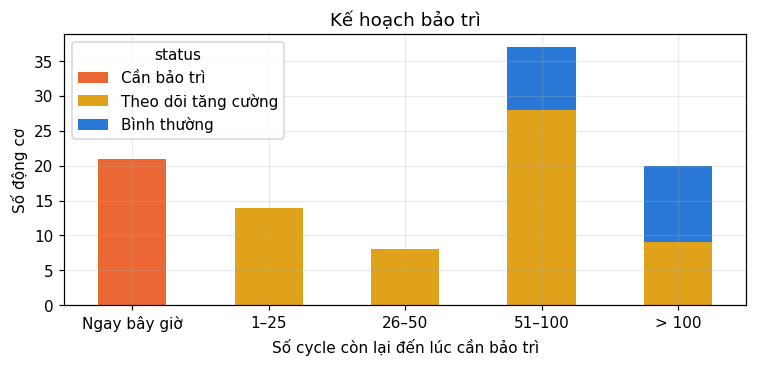

status,Cần bảo trì,Theo dõi tăng cường,Bình thường
Ngay bây giờ,21,0,0
1–25,0,14,0
26–50,0,8,0
51–100,0,28,9
> 100,0,9,11


In [10]:
windows = {"Ngay bây giờ": (0, 0), "1–25": (1, 25), "26–50": (26, 50), "51–100": (51, 100), "> 100": (101, 10_000)}
planning = pd.DataFrame({
    label: schedule.loc[schedule["cycles_to_maintenance"].between(low, high), "status"].value_counts().reindex(STATUS_ORDER, fill_value=0)
    for label, (low, high) in windows.items()
}).T
assert planning.sum(axis=1).to_dict() == maintenance_summary["planning"]
planning.plot(kind="bar", stacked=True, color=["#eb6834", "#e0a21b", "#2a78d6"], figsize=(8, 3.2), rot=0,
              xlabel="Số cycle còn lại đến lúc cần bảo trì", ylabel="Số động cơ", title="Kế hoạch bảo trì")
plt.show()
planning

## 4. Kiểm tra lịch bằng nhãn test

Nhãn `RUL_FD001.txt` chỉ được đọc ở bước này, sau khi lịch đã được lập và so khớp
với artifact. Bảng chéo đặt trạng thái dự đoán cạnh RUL thật.

In [11]:
labels = read_test_labels(ROOT / "data/raw/RUL_FD001.txt")
crosstab, evaluation = evaluate_schedule(schedule, labels, MaintenanceConfig())
stored_check = pd.read_csv(ROOT / "outputs/maintenance/tables/status_vs_actual.csv", index_col=0)
assert crosstab.to_numpy().tolist() == stored_check.to_numpy().tolist()
assert evaluation == maintenance_summary["evaluation"]
print(f"Thật sự cần bảo trì (RUL thật ≤ 30): {evaluation['n_actual_needs_maintenance']}")
print(f"Báo cần bảo trì: {evaluation['n_flagged_needs_maintenance']}, trong đó đúng: {evaluation['n_correct_needs_maintenance']}")
print(f"Báo cần bảo trì nhưng RUL thật còn trên 30: {evaluation['n_flagged_but_actual_above_threshold']}")
print(f"Sai số tuyệt đối trung bình của số cycle còn lại đến lúc bảo trì: {evaluation['cycles_to_maintenance_mae']:.2f}")
crosstab

Thật sự cần bảo trì (RUL thật ≤ 30): 25
Báo cần bảo trì: 21, trong đó đúng: 21
Báo cần bảo trì nhưng RUL thật còn trên 30: 0
Sai số tuyệt đối trung bình của số cycle còn lại đến lúc bảo trì: 14.21


actual_rul,≤ 30,31–60,> 60
status,,,
Cần bảo trì,21,0,0
Theo dõi tăng cường,4,14,41
Bình thường,0,0,20


In [12]:
missed = schedule.merge(labels[["engine_id", "rul"]], on="engine_id")
missed[(missed["rul"] <= 30) & (missed["status"] != STATUS_ORDER[0])][
    ["engine_id", "current_cycle", "rul_pred", "cycles_to_maintenance", "rul", "status"]
]

,engine_id,current_cycle,rul_pred,cycles_to_maintenance,rul,status
21,90,146,31.2191,1,28,Theo dõi tăng cường
22,37,121,31.3637,1,21,Theo dõi tăng cường
25,18,133,37.3757,7,28,Theo dõi tăng cường
26,40,133,38.4593,8,28,Theo dõi tăng cường


## Kết luận

- EWMA span 10 giảm khoảng 86% dao động ngắn hạn của 14 sensor mà vẫn giữ xu hướng
  suy giảm.
- Health Index từ tín hiệu đã khử nhiễu phát hiện bất thường ở 100/100 động cơ train,
  trung vị 121 cycle trước khi hỏng.
- Lịch bảo trì báo cần bảo trì ngay 21 động cơ test và cả 21 đều đúng. Bốn động cơ còn
  lại thật sự cần bảo trì (18, 37, 40, 90) có RUL dự đoán 31–38, nên đến hạn sau 1–8
  cycle và vẫn ở mức theo dõi tăng cường.

**Giới hạn.** Mức theo dõi tăng cường còn rộng: 41/59 động cơ ở mức này có RUL thật
trên 60, nên mức này chỉ phù hợp để tăng tần suất kiểm tra. Lịch có thể quá lạc quan
với từng động cơ (ví dụ động cơ 23). Ngưỡng 30 cycle chưa được hiệu chuẩn theo chi phí
bảo trì vì dữ liệu không có thông tin chi phí.